<a href="https://colab.research.google.com/github/gpgovindapromod/aiml/blob/main/supportvector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np

# Upload dataset
uploaded = files.upload()

# Load dataset
df = pd.read_csv("mcu.csv")

# Fill missing numerical values
numeric_cols = df.select_dtypes(
    include=['float64', 'int64']
).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values
text_cols = df.select_dtypes(
    include=['object']
).columns

for col in text_cols:
    df[col] = df[col].fillna('Unknown')

# Convert release date
df['release_date'] = pd.to_datetime(
    df['release_date'],
    errors='coerce'
)

df['release_year'] = df['release_date'].dt.year
df['release_month'] = df['release_date'].dt.month

# Create classification target
df['tomato_class'] = pd.cut(
    df['tomato_meter'],
    bins=[-1, 59, 79, 100],
    labels=['Low', 'Medium', 'High']
)

print("Dataset shape:", df.shape)

print("\nClass distribution:")
print(df['tomato_class'].value_counts())

display(df.head())

Saving mcu.csv to mcu.csv
Dataset shape: (62, 13)

Class distribution:
tomato_class
High      42
Medium    16
Low        4
Name: count, dtype: int64


,movie_title,mcu_phase,release_date,tomato_meter,audience_score,movie_duration,production_budget,opening_weekend,domestic_box_office,worldwide_box_office,release_year,release_month,tomato_class
0,Iron Man,Phase 1,2008-05-02,94,91,126.0,140000000.0,102118668.0,319034126.0,585796247.0,2008,5,High
1,The Incredible Hulk,Phase 1,2008-06-13,67,70,112.0,137500000.0,55414050.0,134806913.0,265573859.0,2008,6,Medium
2,Iron Man 2,Phase 1,2010-05-07,72,71,124.0,200000000.0,128122480.0,312433331.0,621156389.0,2010,5,Medium
3,Thor,Phase 1,2011-05-06,77,76,114.0,150000000.0,65723338.0,181030624.0,449326618.0,2011,5,Medium
4,Captain America The First Avenger,Phase 1,2011-07-22,80,75,124.0,140000000.0,65058524.0,176654505.0,370569774.0,2011,7,High


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Select features
features = [
    'mcu_phase',
    'audience_score',
    'movie_duration',
    'production_budget',
    'opening_weekend',
    'domestic_box_office',
    'worldwide_box_office',
    'release_year',
    'release_month'
]

X = df[features]
y = df['tomato_class']

# Encode categorical variable
X = pd.get_dummies(
    X,
    columns=['mcu_phase'],
    drop_first=True
)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create Support Vector Classifier
svc_model = SVC(
    kernel='rbf',
    C=1.0,
    random_state=42
)

# Train model
svc_model.fit(
    X_train_scaled,
    y_train
)

# Predictions
y_pred = svc_model.predict(
    X_test_scaled
)

# Calculate metrics
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

print("=" * 50)
print("SUPPORT VECTOR CLASSIFICATION RESULTS")
print("=" * 50)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

SUPPORT VECTOR CLASSIFICATION RESULTS
Accuracy  : 0.6154
Precision : 0.4615
Recall    : 0.6154
F1 Score  : 0.5275

Classification Report:
              precision    recall  f1-score   support

        High       0.67      0.89      0.76         9
         Low       0.00      0.00      0.00         1
      Medium       0.00      0.00      0.00         3

    accuracy                           0.62        13
   macro avg       0.22      0.30      0.25        13
weighted avg       0.46      0.62      0.53        13



Confusion Matrix:
[[8 0 1]
 [1 0 0]
 [3 0 0]]


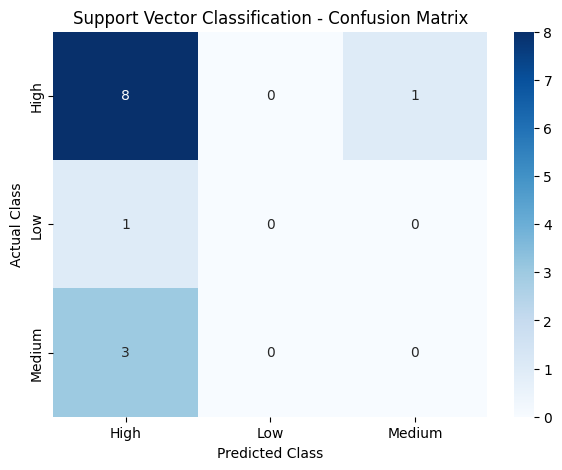

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=svc_model.classes_,
    yticklabels=svc_model.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Support Vector Classification - Confusion Matrix")

plt.show()